In [29]:
import numpy as np
import matplotlib.pyplot as plt

iris = np.genfromtxt('data/iris_full.csv', delimiter=',', skip_header=1)
X = iris[:, :-1]
Y = iris[:, -1]
intercept = np.ones((X.shape[0], 1))
X = np.concatenate((intercept, X), axis = 1)

inds = np.arange(X.shape[0])
np.random.shuffle(inds)

X = X[inds]
Y = Y[inds]

In [30]:
X

array([[1. , 5. , 3.5, 1.6, 0.6],
       [1. , 5.2, 2.7, 3.9, 1.4],
       [1. , 4.5, 2.3, 1.3, 0.3],
       [1. , 5.6, 2.9, 3.6, 1.3],
       [1. , 5.2, 3.4, 1.4, 0.2],
       [1. , 4.8, 3. , 1.4, 0.3],
       [1. , 5. , 2. , 3.5, 1. ],
       [1. , 6.1, 2.9, 4.7, 1.4],
       [1. , 4.4, 3. , 1.3, 0.2],
       [1. , 6.1, 2.8, 4.7, 1.2],
       [1. , 5.8, 4. , 1.2, 0.2],
       [1. , 6.4, 3.2, 4.5, 1.5],
       [1. , 6.2, 2.9, 4.3, 1.3],
       [1. , 5.5, 2.3, 4. , 1.3],
       [1. , 4.4, 2.9, 1.4, 0.2],
       [1. , 5.1, 3.4, 1.5, 0.2],
       [1. , 5. , 3.5, 1.3, 0.3],
       [1. , 5.6, 3. , 4.1, 1.3],
       [1. , 5.4, 3.4, 1.5, 0.4],
       [1. , 4.6, 3.2, 1.4, 0.2],
       [1. , 4.9, 3.1, 1.5, 0.1],
       [1. , 5.1, 3.8, 1.5, 0.3],
       [1. , 5.5, 4.2, 1.4, 0.2],
       [1. , 4.9, 2.4, 3.3, 1. ],
       [1. , 6.1, 2.8, 4. , 1.3],
       [1. , 4.8, 3.4, 1.6, 0.2],
       [1. , 5.7, 2.8, 4.5, 1.3],
       [1. , 5.1, 3.5, 1.4, 0.3],
       [1. , 5.7, 3. , 4.2, 1.2],
       [1. , 4

In [31]:
Y

array([0., 1., 0., 1., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1., 0., 0., 0.,
       1., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 1.,
       0., 0., 1., 1., 0., 1., 1., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.,
       0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 0., 0., 0., 1.,
       0., 1., 1., 0., 0., 1., 0., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0.,
       1., 1., 1., 1., 0., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1.])

In [32]:
def tanh_function(z):
    return(np.exp(z) - np.exp(-z)) / (np.exp(z) + np.exp(-z))

def loss_function(y_hat, y):
    h_scale = (y_hat + 1) / 2
    return (-y * np.log(h_scale) - (1 - y) * np.log(1 - h_scale)).mean()

def predict(X, theta):
    y_hat = tanh_function(np.dot(X, theta))
    return y_hat

def compute_gradient(X, y_hat, y):
    return np.dot(X.T, (y_hat + 1 - 2 * y)) / y.size

lr = 0.01
num_iter = 500
theta = np.array([0.1, 0.5, 0.1, 0.5, -0.1])
losses = []
accs = []
for i in range(num_iter):
    # predict output
    y_hat = predict(X, theta)

    # compute loss
    loss = loss_function(y_hat, Y)

    # compute mean of gradient
    gradient = compute_gradient(X, y_hat, Y)

    # update
    theta -= lr * gradient

    # for debug
    losses.append(loss)

    # accuracy for training
    preds = predict(X, theta).round() / 2 + 0.5
    acc = (preds == Y).mean()
    accs.append(acc)

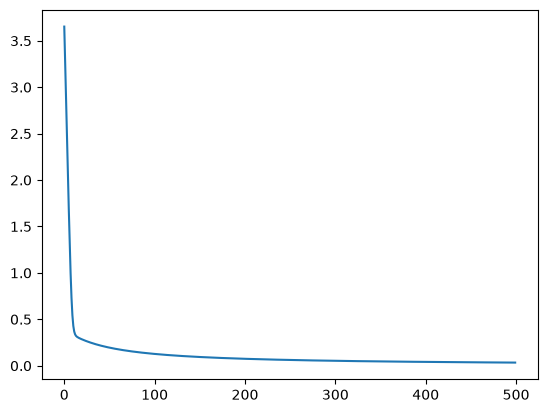

In [33]:
plt.plot(losses)
plt.show()

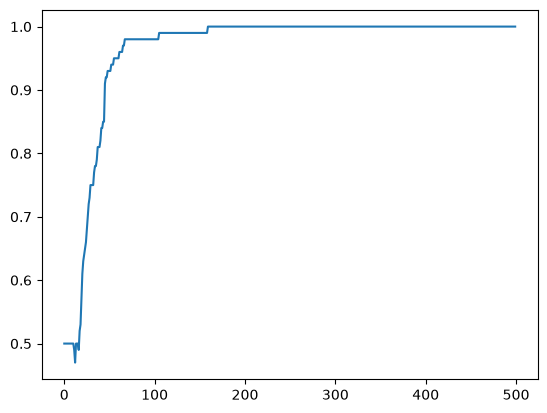

In [34]:
plt.plot(accs)
plt.show()